# 04 - Thống kê mô tả trên dữ liệu Pima Indians Diabetes

Mục tiêu: bài tập thực hành 2 (mục 1.1.4). Dữ liệu gồm 768 dòng và biến `Outcome` (1 = bị tiểu đường).

## 1. Load data và kiểm tra chất lượng

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

pima = pd.read_csv(can_file('pima_diabetes.csv', 'diabetes.csv'))
if 'Glucose' not in pima.columns:
    raise ValueError('File này không phải Pima Indians Diabetes (thiếu cột Glucose). '
                     'Đặt file Pima vào data/pima_diabetes.csv; diabetes.csv của bài Lab05 là bộ Diabetes prediction.')
kiem_tra_chat_luong(pima, 'Pima Diabetes')
display(pima.head())

=== Pima Diabetes ===
Shape: (768, 9)
Số dòng trùng lặp: 0
Giá trị thiếu theo cột:
  Không có giá trị thiếu


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Tiền xử lý: giá trị 0 thực chất là thiếu

Glucose, BloodPressure, SkinThickness, Insulin và BMI không thể bằng 0 về mặt y khoa, nên số 0 ở các cột này là giá trị thiếu được mã hóa. Chuyển về NaN rồi điền bằng trung vị (dữ liệu lệch phải).

,Glucose,BloodPressure,SkinThickness,Insulin,BMI
so_dong_bang_0,5,35,227,374,11


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
missing_pct,0.0,0.65,4.56,29.56,48.7,1.43,0.0,0.0,0.0


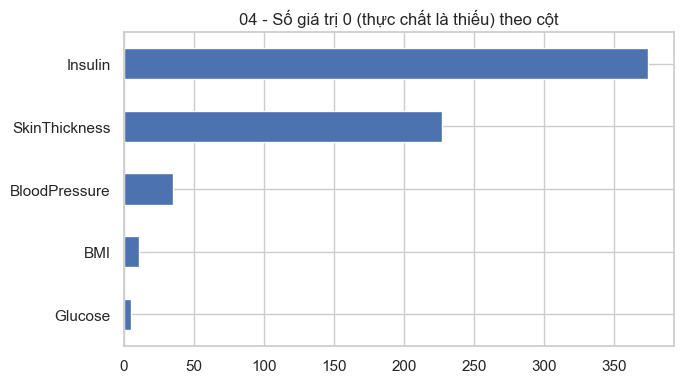

In [2]:
cot_khong_the_bang_0 = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
so_0 = (pima[cot_khong_the_bang_0] == 0).sum()
display(so_0.to_frame('so_dong_bang_0').T)

pima_nan = pima.copy()
pima_nan[cot_khong_the_bang_0] = pima_nan[cot_khong_the_bang_0].replace(0, np.nan)
display((pima_nan.isna().mean() * 100).round(2).to_frame('missing_pct').T)

pima_clean = pima_nan.copy()
for c in cot_khong_the_bang_0:
    pima_clean[c] = pima_clean[c].fillna(pima_clean[c].median())
assert pima_clean.isna().sum().sum() == 0

plt.figure(figsize=(7, 4))
so_0.sort_values().plot.barh()
plt.title('04 - Số giá trị 0 (thực chất là thiếu) theo cột')
luu_hinh('04_pima_zero_as_missing')

## 3. Thống kê mô tả

,count,mean,median,mode,variance,std,min,max,range,P60,Q1,Q2,Q3,IQR,skew,kurtosis,so_outlier_iqr
Pregnancies,768.0,3.845,3.000,1.000,11.354,3.370,0.000,17.00,17.000,4.000,1.000,3.000,6.000,5.000,0.902,0.159,4.0
Glucose,768.0,121.656,117.000,99.000,926.489,30.438,44.000,199.00,155.000,125.000,99.750,117.000,140.250,40.500,0.536,-0.258,0.0
BloodPressure,768.0,72.387,72.000,72.000,146.329,12.097,24.000,122.00,98.000,74.000,64.000,72.000,80.000,16.000,0.142,1.098,14.0
SkinThickness,768.0,29.108,29.000,29.000,77.286,8.791,7.000,99.00,92.000,29.000,25.000,29.000,32.000,7.000,0.838,5.431,87.0
Insulin,768.0,140.672,125.000,125.000,7462.033,86.383,14.000,846.00,832.000,125.000,121.500,125.000,127.250,5.750,3.380,16.232,346.0
BMI,768.0,32.455,32.300,32.300,47.268,6.875,18.200,67.10,48.900,33.700,27.500,32.300,36.600,9.100,0.599,0.920,8.0
DiabetesPedigreeFunction,768.0,0.472,0.372,0.254,0.110,0.331,0.078,2.42,2.342,0.454,0.244,0.372,0.626,0.382,1.920,5.595,29.0
Age,768.0,33.241,29.000,22.000,138.303,11.760,21.000,81.00,60.000,33.000,24.000,29.000,41.000,17.000,1.130,0.643,9.0
Outcome,768.0,0.349,0.000,0.000,0.227,0.477,0.000,1.00,1.000,0.000,0.000,0.000,1.000,1.000,0.635,-1.601,0.0


Tỉ lệ Outcome (%):
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


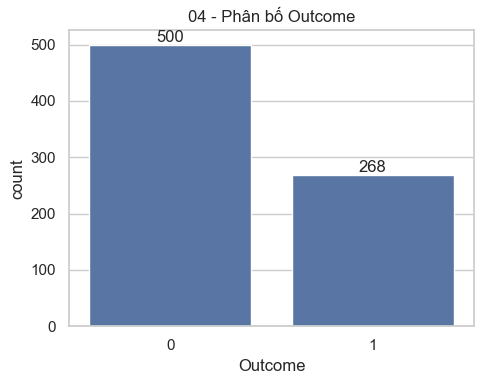

Outcome,median Outcome=0,median Outcome=1
Pregnancies,2.00,4.00
Glucose,107.50,140.00
BloodPressure,72.00,74.00
SkinThickness,29.00,29.00
Insulin,125.00,125.00
BMI,30.40,34.25
DiabetesPedigreeFunction,0.34,0.45
Age,27.00,36.00


Biến có trung vị chênh lệch nhiều nhất giữa hai nhóm (chuẩn hóa theo std):
Glucose        1.068
Age            0.765
Pregnancies    0.594
dtype: float64
Đã cập nhật: results_summary.csv


In [3]:
tk = mo_ta_thong_ke(pima_clean)
display(tk.round(3))
tk.round(4).to_csv(FIG_DIR / '04_pima_descriptive_stats.csv')

ty_le = pima_clean['Outcome'].value_counts(normalize=True).sort_index().mul(100).round(2)
print('Tỉ lệ Outcome (%):'); print(ty_le)
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=pima_clean, x='Outcome')
ax.bar_label(ax.containers[0])
plt.title('04 - Phân bố Outcome')
luu_hinh('04_pima_outcome_distribution')

med = pima_clean.groupby('Outcome').median()
display(med.T.round(2).rename(columns={0: 'median Outcome=0', 1: 'median Outcome=1'}))
chenh = ((med.loc[1] - med.loc[0]) / pima_clean.std()).abs().drop('Outcome')
print('Biến có trung vị chênh lệch nhiều nhất giữa hai nhóm (chuẩn hóa theo std):')
print(chenh.sort_values(ascending=False).head(3).round(3))
cap_nhat_summary('04_diabetes_descriptive', 'Pima Indians Diabetes', pima_clean)

## 4. Nhận xét

Insulin và SkinThickness có nhiều giá trị 0 nhất nên chúng bị ảnh hưởng nhiều nhất bởi cách điền thiếu; điền median là lựa chọn an toàn vì phân bố lệch phải. Lớp `Outcome` mất cân bằng nhẹ (nhóm không bệnh nhiều hơn). So sánh trung vị theo nhóm cho thấy biến nào phân tách hai nhóm rõ nhất, làm cơ sở chọn đặc trưng cho các bài phân loại sau.